# Issue 540: cosmoDC2 cluster run before and after the pairs rewrite

This notebook compares two runs of the cluster stages on the full cosmoDC2 sample (440 deg², 2,658 redMaPPer clusters in 24 redshift/richness bins), at CC-IN2P3:

- **old**: the July 2026 run of the paper baseline, with TXPipe before issue 540. `CLClusterShearCatalogs` computed the shears and weights and wrote them in the pairs file.
- **new**: the same configuration with this branch. `CLClusterSourceSelect` (then called `CLClusterShearCatalogs`) writes only the pairs, and `CLClusterEnsembleProfiles` computes the shears, weights and profiles.

Both use the true-redshift cut and Σcrit (Δz = 0.2), an 8 Mpc search radius, true shears, and ΔΣ from 1.1 to 3.68 Mpc in 7 bins. The new run keeps the sources in the tomographic bin [0.1, 3.0), like the old one (`require_tomo_bin`).

In [1]:
import pickle
import h5py
import numpy as np
import sacc
import matplotlib.pyplot as plt

D = "/sps/lsst/groups/clusters/cl_pipeline_project/TXPipe_data/cosmodc2"
old = f"{D}/outputs-full-2026"
new = f"{D}/outputs-full-2026-issue540-rebuild"


## Pairs

The old pairs file is `cluster_shear_catalogs.hdf5`, the new one `cluster_shear_selection.hdf5`. Both list, cluster by cluster, the row of each source in the shear catalog.

In [2]:
with h5py.File(f"{old}/cluster_shear_catalogs.hdf5", "r") as fo, h5py.File(f"{new}/cluster_shear_selection.hdf5", "r") as fn:
    ids_old, ids_new = fo["catalog/cluster_id"][:], fn["catalog/cluster_id"][:]
    count_old, count_new = fo["catalog/cluster_sample_count"][:], fn["catalog/cluster_sample_count"][:]
    start_old, start_new = fo["catalog/cluster_sample_start"][:], fn["catalog/cluster_sample_start"][:]
    print(f"clusters: {ids_old.size:,} old, {ids_new.size:,} new, same order: {np.array_equal(ids_old, ids_new)}")
    print(f"pairs: {count_old.sum():,} old, {count_new.sum():,} new; clusters with a different number of sources: {(count_old != count_new).sum()}")

    # compare the source lists and distances of 300 random clusters
    rng = np.random.default_rng(0)
    n_same = 0
    for i in rng.choice(np.flatnonzero(count_old > 0), 300, replace=False):
        rows_old = slice(start_old[i], start_old[i] + count_old[i])
        rows_new = slice(start_new[i], start_new[i] + count_new[i])
        n_same += np.array_equal(fo["index/source_index"][rows_old], fn["index/source_index"][rows_new]) and np.allclose(
            fo["index/distance_arcmin"][rows_old], fn["index/distance_arcmin"][rows_new], rtol=1e-12, atol=0
        )
    print(f"{n_same}/300 random clusters with the same sources and distances")


clusters: 45,081 old, 45,081 new, same order: True
pairs: 774,711,934 old, 774,711,934 new; clusters with a different number of sources: 0


300/300 random clusters with the same sources and distances


## Profile of each cluster

The profiles pickle has, for each bin, a CLMM `ClusterEnsemble` with the profile of each cluster.

In [3]:
def profiles(path):
    out = {}
    for key, value in pickle.load(open(path, "rb")).items():
        for row in value["clmm_cluster_ensemble"].data:
            out[int(row["cluster_id"])] = np.asarray(row["tangential_comp"], dtype=float)
    return out

prof_old = profiles(f"{old}/cluster_profiles.pkl")
prof_new = profiles(f"{new}/cluster_profiles.pkl")
print(f"clusters with a profile: {len(prof_old):,} old, {len(prof_new):,} new, same clusters: {prof_old.keys() == prof_new.keys()}")
rel = max(np.nanmax(np.abs(prof_new[c] - prof_old[c]) / np.abs(prof_old[c])) for c in prof_old)
print(f"largest relative difference of the per-cluster Delta Sigma: {rel:.1e}")


clusters with a profile: 2,658 old, 2,658 new, same clusters: True
largest relative difference of the per-cluster Delta Sigma: 4.8e-12


## Stacked ΔΣ and cluster counts in the SACC files

The covariance is a bootstrap, so it changes from run to run. We compare the data points.

In [4]:
s_old = sacc.Sacc.load_fits(f"{old}/cluster_sacc_catalog.sacc")
s_new = sacc.Sacc.load_fits(f"{new}/cluster_sacc_catalog.sacc")
for data_type in ("cluster_counts", "cluster_delta_sigma"):
    a = {tuple(d.tracers): d.value for d in s_old.get_data_points(data_type)}
    b = {tuple(d.tracers): d.value for d in s_new.get_data_points(data_type)}
    worst = max(abs(b[k] - a[k]) / abs(a[k]) for k in a)
    print(f"{data_type}: {len(a)} old, {len(b)} new points, same tracers: {a.keys() == b.keys()}, largest relative difference {worst:.1e}")


cluster_counts: 24 old, 24 new points, same tracers: True, largest relative difference 0.0e+00
cluster_delta_sigma: 168 old, 168 new points, same tracers: True, largest relative difference 5.9e-15


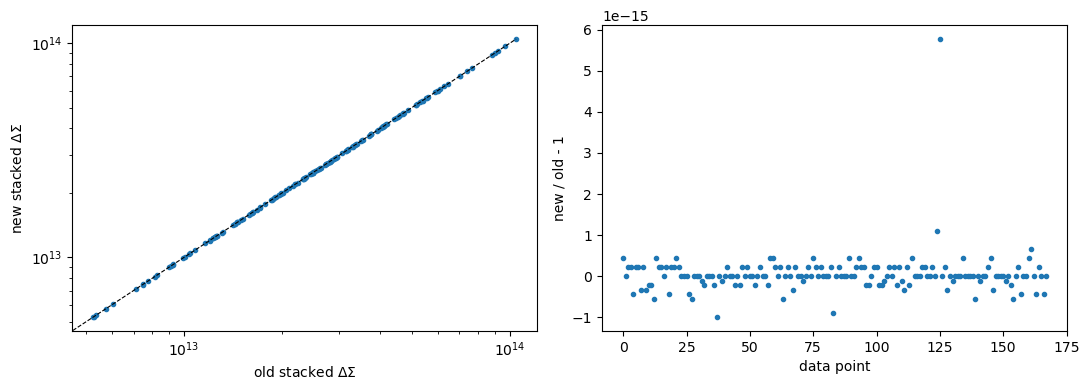

In [5]:
ds_old = {tuple(d.tracers): d.value for d in s_old.get_data_points("cluster_delta_sigma")}
ds_new = {tuple(d.tracers): d.value for d in s_new.get_data_points("cluster_delta_sigma")}
keys = sorted(ds_old)
x, y = np.array([ds_old[k] for k in keys]), np.array([ds_new[k] for k in keys])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.loglog(x, y, ".")
ax1.plot([x.min(), x.max()], [x.min(), x.max()], "k--", lw=0.8)
ax1.set_xlabel("old stacked $\\Delta\\Sigma$")
ax1.set_ylabel("new stacked $\\Delta\\Sigma$")
ax2.plot(y / x - 1, ".")
ax2.set_xlabel("data point")
ax2.set_ylabel("new / old - 1")
plt.tight_layout()
plt.show()
